In [220]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [221]:
pd.set_option('display.max_columns', None) ## despliega todas las columnas

In [222]:
df=pd.read_csv("../data/raw/smoking_prediction_etiquetado.csv")
df.head(4)

,ID,gender,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),systolic,relaxation,fasting blood sugar,Cholesterol,triglyceride,HDL,LDL,hemoglobin,Urine protein,serum creatinine,AST,ALT,Gtp,oral,dental caries,tartar,smoking
0,0,F,40,155,60,3.38,0.04,0.04,0.04,0.04,4.75,3.04,3.92,8.96,3.42,3.04,5.25,0.51,0.04,0.00,0.75,0.79,1.13,Y,0,Y,0
1,1,F,40,160,60,3.38,0.01,0.00,0.04,0.04,4.96,2.92,5.42,8.00,4.79,1.75,5.29,0.50,0.04,0.00,0.92,0.79,0.75,Y,0,Y,0
2,2,M,55,170,60,3.33,0.01,0.01,0.04,0.04,5.75,3.58,3.71,10.08,7.58,2.29,6.29,0.63,0.04,0.04,0.88,0.67,0.92,Y,0,N,1
3,3,M,40,165,70,3.67,0.05,0.05,0.04,0.04,4.17,2.50,4.00,13.42,10.58,1.88,9.42,0.59,0.04,0.04,0.79,1.08,0.75,Y,0,Y,0


# Limpieza y feature engineering

Eimino variables ID y oral

In [223]:
df=df.drop(columns=['ID','oral']) ## elimnación de identificador y "oral" (valor constante)

In [224]:
df.shape

(50000, 25)

In [225]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   gender               50000 non-null  str    
 1   age                  50000 non-null  int64  
 2   height(cm)           50000 non-null  int64  
 3   weight(kg)           50000 non-null  int64  
 4   waist(cm)            50000 non-null  float64
 5   eyesight(left)       50000 non-null  float64
 6   eyesight(right)      50000 non-null  float64
 7   hearing(left)        50000 non-null  float64
 8   hearing(right)       50000 non-null  float64
 9   systolic             50000 non-null  float64
 10  relaxation           50000 non-null  float64
 11  fasting blood sugar  50000 non-null  float64
 12  Cholesterol          50000 non-null  float64
 13  triglyceride         50000 non-null  float64
 14  HDL                  50000 non-null  float64
 15  LDL                  50000 non-null  float64
 1

Eliminación de filas duplicadas

In [226]:
df.duplicated().value_counts() ## filas duplicadas --> eliminar y dejar 1

False    44552
True      5448
Name: count, dtype: int64

In [227]:
## elimino duplicados dejando la primer ocurrencia
columns=df.columns
df=df.drop_duplicates(subset=columns, keep='first')

In [228]:
df.shape

(44552, 25)

In [229]:
df.describe()

,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),systolic,relaxation,fasting blood sugar,Cholesterol,triglyceride,HDL,LDL,hemoglobin,Urine protein,serum creatinine,AST,ALT,Gtp,dental caries,smoking
count,44552.000000,44552.000000,44552.000000,44552.000000,44552.000000,44552.000000,44552.000000,44552.000000,44552.000000,44552.000000,44552.000000,44552.000000,44552.000000,44552.000000,44552.000000,44552.000000,44552.000000,44552.000000,44552.000000,44552.000000,44552.000000,44552.000000,44552.000000
mean,44.210698,164.657030,65.883462,3.416172,0.027994,0.027891,0.041024,0.041041,5.064384,3.169055,4.139159,8.208974,5.280922,2.387821,4.794074,0.594430,0.043711,0.018543,1.093078,1.129391,1.670259,0.213526,0.367032
std,12.089196,9.198674,12.823819,0.386461,0.024247,0.024240,0.006319,0.006370,0.570438,0.403839,0.868572,1.517640,2.983872,0.616463,1.705766,0.066451,0.017513,0.017572,0.795324,1.323135,2.113498,0.409800,0.482001
min,20.000000,130.000000,30.000000,2.130000,0.000000,0.000000,0.040000,0.040000,2.960000,1.670000,1.920000,2.290000,0.330000,0.170000,0.040000,0.170000,0.040000,0.000000,0.250000,0.040000,0.040000,0.000000,0.000000
25%,40.000000,160.000000,55.000000,3.170000,0.010000,0.010000,0.040000,0.040000,4.670000,2.920000,3.710000,7.170000,3.080000,1.960000,3.830000,0.550000,0.040000,0.010000,0.790000,0.630000,0.710000,0.000000,0.000000
50%,40.000000,165.000000,65.000000,3.420000,0.040000,0.040000,0.040000,0.040000,5.000000,3.170000,4.000000,8.130000,4.500000,2.290000,4.710000,0.590000,0.040000,0.010000,0.960000,0.880000,1.080000,0.000000,0.000000
75%,55.000000,170.000000,75.000000,3.670000,0.040000,0.040000,0.040000,0.040000,5.420000,3.420000,4.330000,9.170000,6.670000,2.750000,5.670000,0.630000,0.040000,0.040000,1.210000,1.290000,1.830000,0.000000,1.000000
max,85.000000,190.000000,135.000000,5.380000,0.380000,0.380000,0.080000,0.080000,10.000000,6.080000,21.040000,18.540000,41.630000,25.750000,77.500000,0.880000,0.250000,0.460000,54.630000,121.420000,41.630000,1.000000,1.000000


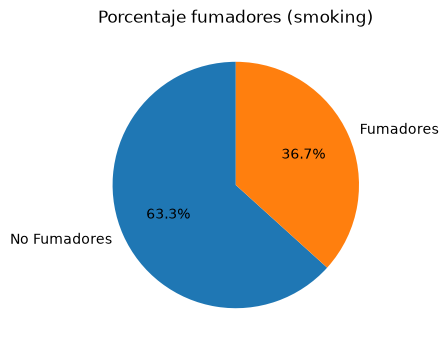

In [230]:
## Representación de la variable objetivo después de quitar duplicaodos
## Variable objetivo: representación
plt.figure(figsize=(6,4))
smoking_count = df.smoking.value_counts(normalize=True)*100
plt.pie(smoking_count, labels=["No Fumadores","Fumadores"], autopct="%1.1f%%", startangle=90)
plt.title("Porcentaje fumadores (smoking)")
plt.show()

Codificación de las variables : gender, tartar, hearing(left), hearing(right)

In [231]:
df['gender']=(df['gender'] == "M").astype(int)  ## F=0, M=1
df['tartar']=(df['tartar'] == "Y").astype(int)  ## N=0, Y=1

In [232]:
## las variables 'hearing(left)', 'hearing(right)', toma valores 0.04 y 0.08 --> convierto a binarias
df['hearing(left)']=(df['hearing(left)'] > 0.04).astype(int)  ## 0.04=0, 0.08=1
df['hearing(right)']=(df['hearing(right)'] > 0.04).astype(int)  ## 0.04=0, 0.08=1

In [233]:
df.columns

Index(['gender', 'age', 'height(cm)', 'weight(kg)', 'waist(cm)',
       'eyesight(left)', 'eyesight(right)', 'hearing(left)', 'hearing(right)',
       'systolic', 'relaxation', 'fasting blood sugar', 'Cholesterol',
       'triglyceride', 'HDL', 'LDL', 'hemoglobin', 'Urine protein',
       'serum creatinine', 'AST', 'ALT', 'Gtp', 'dental caries', 'tartar',
       'smoking'],
      dtype='str')

In [234]:
df['hearing(left)'].unique()

array([0, 1])

In [235]:
df['hearing(right)'].unique()

array([0, 1])

In [236]:
df.head(4)

,gender,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),systolic,relaxation,fasting blood sugar,Cholesterol,triglyceride,HDL,LDL,hemoglobin,Urine protein,serum creatinine,AST,ALT,Gtp,dental caries,tartar,smoking
0,0,40,155,60,3.38,0.04,0.04,0,0,4.75,3.04,3.92,8.96,3.42,3.04,5.25,0.51,0.04,0.00,0.75,0.79,1.13,0,1,0
1,0,40,160,60,3.38,0.01,0.00,0,0,4.96,2.92,5.42,8.00,4.79,1.75,5.29,0.50,0.04,0.00,0.92,0.79,0.75,0,1,0
2,1,55,170,60,3.33,0.01,0.01,0,0,5.75,3.58,3.71,10.08,7.58,2.29,6.29,0.63,0.04,0.04,0.88,0.67,0.92,0,0,1
3,1,40,165,70,3.67,0.05,0.05,0,0,4.17,2.50,4.00,13.42,10.58,1.88,9.42,0.59,0.04,0.04,0.79,1.08,0.75,0,1,0


# Guardado de datos

In [237]:
## datos limpios, split en Train y Test
df.to_csv("../data/processed/preproccesed_smoking_prediction_etiquetado.csv")

# Preparación de Train y Test

In [238]:
X = df.drop(columns=['smoking'])
y = df['smoking']

In [239]:
## Train(70%) y Test(30%): procesamiento de conjuntos
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

In [240]:
print("X_train :", X_train.shape)
print("X_test :", X_test.shape)
print("\ny_train :", y_train.shape)
print("y_test :", y_test.shape)
print("\nTarget en train :", y_train.value_counts(normalize=True)*100)
print("\nTarget en test :", y_test.value_counts(normalize=True)*100)

X_train : (35641, 24)
X_test : (8911, 24)

y_train : (35641,)
y_test : (8911,)

Target en train : smoking
0    63.297887
1    36.702113
Name: proportion, dtype: float64

Target en test : smoking
0    63.29256
1    36.70744
Name: proportion, dtype: float64


In [241]:
X_train.head(4)

,gender,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),systolic,relaxation,fasting blood sugar,Cholesterol,triglyceride,HDL,LDL,hemoglobin,Urine protein,serum creatinine,AST,ALT,Gtp,dental caries,tartar
31742,1,40,170,80,3.80,0.00,0.00,0,0,4.58,2.92,4.04,10.42,12.42,1.83,6.08,0.67,0.04,0.04,1.25,1.54,1.83,0,1
7945,0,45,150,55,3.04,0.00,0.01,0,0,5.46,3.21,3.54,7.08,4.04,2.96,3.54,0.55,0.04,0.04,0.71,0.50,0.46,0,1
27480,1,40,170,60,3.09,0.01,0.00,0,0,5.08,3.50,4.42,9.08,4.17,3.46,4.79,0.63,0.04,0.04,0.83,0.33,1.13,0,1
32289,0,40,150,45,2.92,0.04,0.04,0,0,5.42,3.33,3.75,9.13,2.08,2.92,5.79,0.50,0.04,0.01,0.63,0.38,0.42,0,0


In [242]:
X_test.head(4)

,gender,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),systolic,relaxation,fasting blood sugar,Cholesterol,triglyceride,HDL,LDL,hemoglobin,Urine protein,serum creatinine,AST,ALT,Gtp,dental caries,tartar
16754,1,20,185,100,3.88,0.05,0.04,0,0,5.42,2.83,3.67,7.46,3.08,1.96,4.88,0.63,0.04,0.04,0.75,0.88,1.21,0,1
32962,0,40,165,55,2.92,0.05,0.04,0,0,4.17,3.00,3.92,6.71,2.04,2.54,3.75,0.50,0.04,0.01,0.83,0.96,1.79,0,0
41330,0,60,155,45,2.96,0.00,0.00,0,0,4.92,2.63,3.38,8.88,4.46,3.33,4.63,0.46,0.04,0.00,1.04,0.92,1.29,1,1
39841,0,50,155,45,2.71,0.01,0.04,0,0,4.83,3.08,3.83,8.63,3.67,3.79,4.08,0.54,0.04,0.01,1.13,0.58,0.50,0,0


In [243]:
y_train.head(4)

31742    1
7945     0
27480    1
32289    0
Name: smoking, dtype: int64

In [244]:
y_test.head()

16754    0
32962    0
41330    0
39841    0
10632    0
Name: smoking, dtype: int64

In [245]:
import joblib
joblib.dump((X_train, y_train), "../data/processed/train.joblib") ## Conjunto para entrenamiento y optimización
joblib.dump((X_test, y_test), "../data/processed/test.joblib") ## Conunto para valización 

['../data/processed/test.joblib']